Matplotlib is building the font cache; this may take a moment.


saved


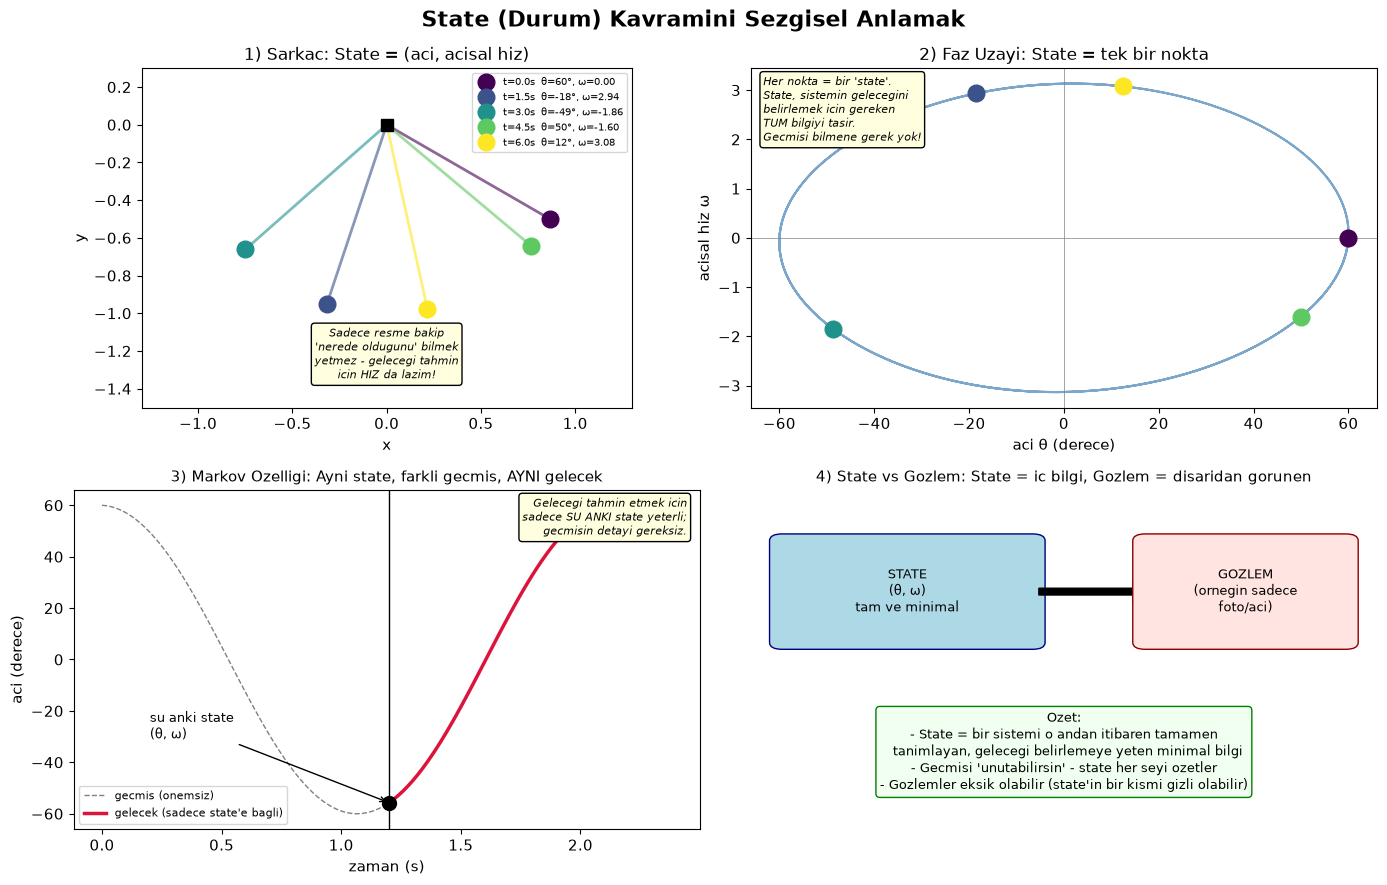

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.rcParams['font.size'] = 11

fig = plt.figure(figsize=(14, 9))
fig.suptitle("State (Durum) Kavramini Sezgisel Anlamak", fontsize=16, fontweight='bold')

# ---------------------------------------------------------
# 1) Sarkac (pendulum) - fiziksel sistem, state = (aci, aci hizi)
# ---------------------------------------------------------
ax1 = fig.add_subplot(2, 2, 1)
ax1.set_title("1) Sarkac: State = (aci, acisal hiz)", fontsize=12)

g, L = 9.81, 1.0
theta0, omega0 = np.radians(60), 0.0
dt = 0.02
T = 6.0
n = int(T/dt)
theta = np.zeros(n); omega = np.zeros(n)
theta[0], omega[0] = theta0, omega0
for i in range(1, n):
    alpha = -(g/L)*np.sin(theta[i-1])
    omega[i] = omega[i-1] + alpha*dt
    theta[i] = theta[i-1] + omega[i]*dt

snap_idx = [0, n//4, n//2, 3*n//4, n-1]
colors = plt.cm.viridis(np.linspace(0, 1, len(snap_idx)))
for c, idx in zip(colors, snap_idx):
    x = L*np.sin(theta[idx]); y = -L*np.cos(theta[idx])
    ax1.plot([0, x], [0, y], '-', color=c, alpha=0.6, lw=2)
    ax1.plot(x, y, 'o', color=c, markersize=12,
              label=f"t={idx*dt:.1f}s  θ={np.degrees(theta[idx]):.0f}°, ω={omega[idx]:.2f}")
ax1.plot(0, 0, 'ks', markersize=8)
ax1.set_xlim(-1.3, 1.3); ax1.set_ylim(-1.5, 0.3)
ax1.set_aspect('equal')
ax1.legend(fontsize=7, loc='upper right')
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.text(0, -1.07, "Sadece resme bakip\n'nerede oldugunu' bilmek\nyetmez - gelecegi tahmin\nicin HIZ da lazim!",
          ha='center', va='top', fontsize=8, style='italic',
          bbox=dict(boxstyle='round', fc='lightyellow'))

# ---------------------------------------------------------
# 2) Faz uzayi (phase space) - state = nokta
# ---------------------------------------------------------
ax2 = fig.add_subplot(2, 2, 2)
ax2.set_title("2) Faz Uzayi: State = tek bir nokta", fontsize=12)
ax2.plot(np.degrees(theta), omega, color='steelblue', lw=1.5, alpha=0.7)
for c, idx in zip(colors, snap_idx):
    ax2.plot(np.degrees(theta[idx]), omega[idx], 'o', color=c, markersize=12, zorder=5)
ax2.axhline(0, color='gray', lw=0.5); ax2.axvline(0, color='gray', lw=0.5)
ax2.set_xlabel("aci θ (derece)")
ax2.set_ylabel("acisal hiz ω")
ax2.text(0.02, 0.98,
          "Her nokta = bir 'state'.\nState, sistemin gelecegini\nbelirlemek icin gereken\nTUM bilgiyi tasir.\nGecmisi bilmene gerek yok!",
          transform=ax2.transAxes, va='top', fontsize=8, style='italic',
          bbox=dict(boxstyle='round', fc='lightyellow'))

# ---------------------------------------------------------
# 3) Markov ozelligi: ayni state -> ayni gelecek
# ---------------------------------------------------------
ax3 = fig.add_subplot(2, 2, 3)
ax3.set_title("3) Markov Ozelligi: Ayni state, farkli gecmis, AYNI gelecek", fontsize=11)

t_future = np.linspace(0, 2, 100)
theta_a, omega_a = np.radians(60), 0.0
theta_b, omega_b = np.radians(20), 0.4

def simulate(theta_i, omega_i, steps=100, dt=0.02):
    th = np.zeros(steps); om = np.zeros(steps)
    th[0], om[0] = theta_i, omega_i
    for i in range(1, steps):
        a = -(g/L)*np.sin(th[i-1])
        om[i] = om[i-1] + a*dt
        th[i] = th[i-1] + om[i]*dt
    return th, om

# iki farkli "gecmis" ayni state'e ulassin (varsayimsal), sonra ortak gelecek
th_common, om_common = simulate(theta0, omega0, steps=int(2.4/dt))
merge_i = int(1.2/dt)
ax3.plot(np.arange(len(th_common))*dt, np.degrees(th_common), color='gray', lw=1, ls='--', label="gecmis (onemsiz)")
ax3.plot(np.arange(merge_i, len(th_common))*dt, np.degrees(th_common[merge_i:]), color='crimson', lw=2.5, label="gelecek (sadece state'e bagli)")
ax3.axvline(merge_i*dt, color='black', lw=1)
ax3.plot(merge_i*dt, np.degrees(th_common[merge_i]), 'ko', markersize=10, zorder=5)
ax3.annotate("su anki state\n(θ, ω)", xy=(merge_i*dt, np.degrees(th_common[merge_i])),
              xytext=(merge_i*dt-1.0, np.degrees(th_common[merge_i])+25),
              arrowprops=dict(arrowstyle='->'), fontsize=9)
ax3.set_xlabel("zaman (s)"); ax3.set_ylabel("aci (derece)")
ax3.legend(fontsize=8, loc='lower left')
ax3.text(0.98, 0.98, "Gelecegi tahmin etmek icin\nsadece SU ANKI state yeterli;\ngecmisin detayi gereksiz.",
          transform=ax3.transAxes, ha='right', va='top', fontsize=8, style='italic',
          bbox=dict(boxstyle='round', fc='lightyellow'))

# ---------------------------------------------------------
# 4) State vs Gozlem (observation) - RL/ML baglaminda
# ---------------------------------------------------------
ax4 = fig.add_subplot(2, 2, 4)
ax4.set_title("4) State vs Gozlem: State = ic bilgi, Gozlem = disaridan gorunen", fontsize=10.5)
ax4.axis('off')

box1 = patches.FancyBboxPatch((0.05, 0.55), 0.4, 0.3, boxstyle="round,pad=0.02",
                                fc='lightblue', ec='navy')
ax4.add_patch(box1)
ax4.text(0.25, 0.7, "STATE\n(θ, ω)\ntam ve minimal", ha='center', va='center', fontsize=9)

arrow = patches.FancyArrow(0.46, 0.7, 0.15, 0, width=0.02, color='black')
ax4.add_patch(arrow)

box2 = patches.FancyBboxPatch((0.63, 0.55), 0.32, 0.3, boxstyle="round,pad=0.02",
                                fc='mistyrose', ec='darkred')
ax4.add_patch(box2)
ax4.text(0.79, 0.7, "GOZLEM\n(ornegin sadece\nfoto/aci)", ha='center', va='center', fontsize=9)

ax4.text(0.5, 0.35,
          "Ozet:\n"
          "- State = bir sistemi o andan itibaren tamamen\n"
          "  tanimlayan, gelecegi belirlemeye yeten minimal bilgi\n"
          "- Gecmisi 'unutabilirsin' - state her seyi ozetler\n"
          "- Gozlemler eksik olabilir (state'in bir kismi gizli olabilir)",
          ha='center', va='top', fontsize=9.5,
          bbox=dict(boxstyle='round', fc='honeydew', ec='green'))

plt.tight_layout()
from pathlib import Path
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)
plt.savefig(out / "04-state-concept.png", dpi=140, bbox_inches="tight")
print("saved")
